# Solutions to the exercises of Chapter 15

Sample solutions for [Chapter 15, Diffusion with reaction](../../notebooks/part4_mass_transfer/15_diffusion_reaction.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

try:
    from engtransport import diffusion
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import diffusion
from engtransport.numerics import bisect
from engtransport.plotting import use_style

use_style()
YEAR = 365.25 * 86400.0

## Exercise 1. A diagnosis from two measurements

The crushed particles are small enough that they should be used fully; the rate constant is
then their observed rate over $c_s$, and the ratio of the two rates is the pellets'
effectiveness factor. Inverting Eq. (15.5) for a sphere gives the modulus, and Eq. (15.4)
the diffusivity. The guess that the crushed particles are fully used is then checked and
the rate constant corrected.

In [2]:
c_s, r_pellet, r_crushed = 1.0, 4.0, 9.5
VA_pellet, VA_crushed = 0.006 / 6, 0.0003 / 6
eta_c = 1.0
for it in range(5):
    k = r_crushed / (eta_c * c_s)
    eta_p = r_pellet / (k * c_s)
    phi_p = bisect(lambda p: diffusion.effectiveness_first_order(p, "sphere") - eta_p, 1e-6, 1e3)[0]
    D_eff = k * VA_pellet**2 / phi_p**2
    eta_c = diffusion.effectiveness_first_order(VA_crushed * math.sqrt(k / D_eff), "sphere")
print(f"pellets: eta = {eta_p:.3f}, phi = {phi_p:.3f}; k = {k:.3f} 1/s, D_eff = {D_eff * 1e6:.3f} mm2/s;"
      f" crushed particles: phi = {VA_crushed * math.sqrt(k / D_eff):.3f}, eta = {eta_c:.4f}")
for label, r, VA in (("6 mm pellets", r_pellet, VA_pellet), ("0.3 mm particles", r_crushed, VA_crushed)):
    print(f"Weisz-Prater modulus, {label}: {diffusion.observable_modulus(r, VA, D_eff, c_s):.4f}")

pellets: eta = 0.419, phi = 1.989; k = 9.556 1/s, D_eff = 2.416 mm2/s; crushed particles: phi = 0.099, eta = 0.9941
Weisz-Prater modulus, 6 mm pellets: 1.6553
Weisz-Prater modulus, 0.3 mm particles: 0.0098


The pellets work at 42 % of their catalyst, with $\phi = 2.0$; the rate constant is
9.6 s⁻¹ and the effective diffusivity 2.4 mm²/s. The crushed particles have $\phi = 0.10$
and $\eta = 0.994$, so the first guess was good to 0.6 %. The Weisz–Prater modulus,
computed from observables alone, is 1.7 for the pellets and 0.010 for the crushed
particles, on either side of 1 as the test requires. Two rate measurements at different
sizes are thus enough to separate kinetics from diffusion, as long as the reaction is
first order.

## Exercise 2. An egg-shell catalyst

With the same total metal in a shell of thickness $\delta$, the activity in the shell is
$A = 1/[1 - (1 - \delta/R)^3]$ times the uniform activity, and zero inside.

uniform pellet: eta = 0.381, bed 0.656 m
shell 0.5 mm: eta = 0.587, bed 0.426 m
thinnest shell at ten times the loading: 0.104 mm, eta = 0.857, bed 0.291 m


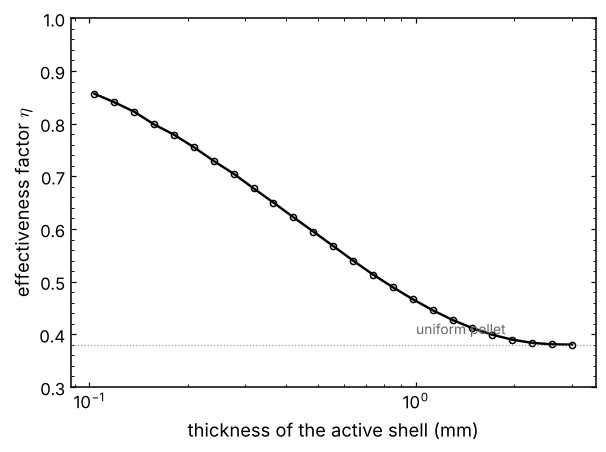

In [3]:
k_v, D_eff2, R, u_s, eps_b, X = 10.0, 2e-6, 0.003, 0.5, 0.4, 0.95
phi = R / 3 * math.sqrt(k_v / D_eff2)


def egg_shell(delta, n=600):
    x_in = 1 - delta / R
    A = 1 / (1 - x_in**3)
    return diffusion.pellet_fd(phi, "sphere", 1.0, n, activity=lambda x: np.where(x >= x_in, A, 0.0))["eta"]


L_bed = lambda eta: u_s * math.log(1 / (1 - X)) / ((1 - eps_b) * eta * k_v)
eta_u = diffusion.effectiveness_first_order(phi, "sphere")
print(f"uniform pellet: eta = {eta_u:.3f}, bed {L_bed(eta_u):.3f} m")
eta_shell = egg_shell(0.0005)
print(f"shell 0.5 mm: eta = {eta_shell:.3f}, bed {L_bed(eta_shell):.3f} m")
delta_min = R * (1 - 0.9 ** (1 / 3))                 # ten times the uniform loading
eta_min = egg_shell(delta_min, 1200)
print(f"thinnest shell at ten times the loading: {1e3 * delta_min:.3f} mm, eta = {eta_min:.3f}, bed {L_bed(eta_min):.3f} m")
deltas = np.geomspace(delta_min, R, 25)
etas = np.array([egg_shell(d, 1200) for d in deltas])
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.semilogx(1e3 * deltas, etas, "ko-", ms=4, mfc="none")
ax.axhline(eta_u, color="0.6", ls=":", lw=0.8)
ax.text(1.0, eta_u + 0.02, "uniform pellet", color="0.4", fontsize=9)
ax.set_xlabel("thickness of the active shell (mm)")
ax.set_ylabel(r"effectiveness factor $\eta$")
ax.set_ylim(0.3, 1.0)
plt.show()

**Figure S15.1.** Effectiveness factor of a 6 mm sphere with all its active metal in an
outer shell, against the shell thickness, with the same total metal.

Moving the same metal into a 0.5 mm shell raises $\eta$ from 0.38 to 0.59 and shortens the
bed from 0.66 to 0.43 m. The thinner the shell, the better: in the limit all the metal sits
where the reactant arrives at full concentration. With a ceiling of ten times the uniform
loading, the thinnest shell is 0.10 mm and gives $\eta = 0.86$, a bed of 0.29 m with the
pressure drop of the 6 mm pellets (0.49 kPa against 2.3 kPa for 1.5 mm pellets of the same
bed length in Section 15.3). Egg-shell pellets combine the low pressure drop of large
pellets with the effectiveness of small ones; their limits are the loading of the support
and the loss of the outer shell by attrition or poisoning.

## Exercise 3. Starting up a pellet

The deviation from the steady state, $w = c - c_{ss}$, obeys the same equation with zero
surface value, so it decays as a sum of modes $\sin(m\pi r/R)/r$, the slowest at the rate
$\lambda_1 = (k + D_{eff}\pi^2/R^2)/0.5$. The numerical solution uses finite volumes in $r$.

In [4]:
eps_p, n = 0.5, 200
r_f = np.linspace(0, R, n + 1)                       # faces
r_c = 0.5 * (r_f[1:] + r_f[:-1])
V = (r_f[1:] ** 3 - r_f[:-1] ** 3) / 3
Af = r_f**2
dr = R / n


def rhs(t, c):
    grad = np.zeros(n + 1)
    grad[1:n] = (c[1:] - c[:-1]) / dr
    grad[n] = (1.0 - c[-1]) / (dr / 2)
    flux = D_eff2 * Af * grad
    return ((flux[1:] - flux[:-1]) - k_v * c * V) / (eps_p * V)


t_ev = np.linspace(0, 0.4, 401)
sol = solve_ivp(rhs, (0, 0.4), np.zeros(n), method="BDF", t_eval=t_ev, rtol=1e-9, atol=1e-12)
rate = (k_v * sol.y * V[:, None]).sum(axis=0)        # reaction rate of the pellet
steady = rate[-1]
i99 = np.argmax(np.abs(rate / steady - 1) < 0.01)
lam1 = (k_v + D_eff2 * math.pi**2 / R**2) / eps_p
print(f"steady effectiveness from the march: {steady / (k_v * R**3 / 3):.4f} (Eq. 15.5: {eta_u:.4f})")
print(f"within 1 % of the steady rate after {1e3 * t_ev[i99]:.0f} ms; slowest decay rate {lam1:.1f} 1/s, time constant {1e3 / lam1:.0f} ms")
late = (t_ev > 0.1) & (t_ev < 0.3)
slope = np.polyfit(t_ev[late & (np.abs(rate / steady - 1) > 1e-9)],
                   np.log(np.abs(1 - rate / steady)[late & (np.abs(rate / steady - 1) > 1e-9)]), 1)[0]
print(f"decay rate of the deviation fitted to the march: {-slope:.1f} 1/s")

steady effectiveness from the march: 0.3805 (Eq. 15.5: 0.3805)
within 1 % of the steady rate after 142 ms; slowest decay rate 24.4 1/s, time constant 41 ms
decay rate of the deviation fitted to the march: 25.4 1/s


The pellet reaches 1 % of its steady rate within 0.14 s, and the deviation decays at
25 s⁻¹, close to the 24.4 s⁻¹ of the slowest mode (the fit still feels the next one). The time constant, 41 ms, is the shorter of the
reaction time $\varepsilon/k$ and the diffusion time $\varepsilon R^2/\pi^2D_{eff}$
combined. Gas concentrations in a converter change over seconds or minutes, so the pellets
follow them in quasi-steady state; this is why the effectiveness factor, a steady-state
quantity, can be used along a reactor and through its transients.

## Exercise 4. A coating on the concrete

The coating adds a resistance in series with the carbonated layer. A coating described by
an equivalent still-air thickness $s_D$ for carbon dioxide has the resistance
$R_c = s_D/D_{CO_2,air}$; take $s_D = 50$ m (an assumed value for a good anti-carbonation
coating) and $D_{CO_2,air} = 1.6\times10^{-5}$ m²/s. Equation (15.10) becomes
$x^2/2D_{eff} + R_c x = c_0 t/a + \text{const}$ (`diffusion.shrinking_core_depth`).

coating resistance 3.12e+06 s/m; carbonated concrete, 25 mm: 2.50e+06 s/m
25 mm reached: bare 85 years; coated when new 298 years; coated at 20 years (front then at 12.1 mm) 194 years


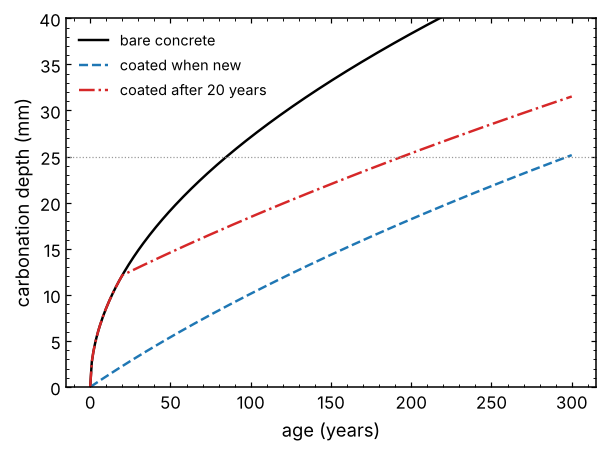

In [5]:
c0, D_c, a_c = 41.6 * 420e-6, 1e-8, 1500.0
R_coat = 50.0 / 1.6e-5
print(f"coating resistance {R_coat:.2e} s/m; carbonated concrete, 25 mm: {0.025 / D_c:.2e} s/m")
t_bare = 0.025**2 * a_c / (2 * D_c * c0)
t_new = a_c * (0.025**2 / (2 * D_c) + R_coat * 0.025) / c0
x20 = diffusion.shrinking_core_depth(20 * YEAR, D_c, c0, a_c)
t_late = 20 * YEAR + a_c * ((0.025**2 - x20**2) / (2 * D_c) + R_coat * (0.025 - x20)) / c0
print(f"25 mm reached: bare {t_bare / YEAR:.0f} years; coated when new {t_new / YEAR:.0f} years;"
      f" coated at 20 years (front then at {1e3 * x20:.1f} mm) {t_late / YEAR:.0f} years")
yrs = np.linspace(0, 300, 301)
x_late = np.where(yrs <= 20, diffusion.shrinking_core_depth(yrs * YEAR, D_c, c0, a_c),
                  diffusion.shrinking_core_depth((yrs - 20) * YEAR, D_c, c0, a_c, x0=x20, R_outer=R_coat))
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.plot(yrs, 1e3 * diffusion.shrinking_core_depth(yrs * YEAR, D_c, c0, a_c), "k-", label="bare concrete")
ax.plot(yrs, 1e3 * diffusion.shrinking_core_depth(yrs * YEAR, D_c, c0, a_c, R_outer=R_coat), "C0--", label="coated when new")
ax.plot(yrs, 1e3 * x_late, "C3-.", label="coated after 20 years")
ax.axhline(25, color="0.6", ls=":", lw=0.8)
ax.set_xlabel("age (years)")
ax.set_ylabel("carbonation depth (mm)")
ax.set_ylim(0, 40)
ax.legend(loc="upper left")
plt.show()

**Figure S15.2.** Carbonation depth of the concrete of Section 15.4, bare and with a
coating applied when new or after 20 years.

The coating resists as much as 31 mm of carbonated concrete. Applied to new concrete it
stretches the time to reach 25 mm from 85 to 298 years; applied after 20 years, when the
front is already 12 mm deep, to 194 years. In both cases the front then advances almost
linearly in time, because the coating, not the growing carbonated layer, controls the flux.
A late coating still pays, as long as it is applied before the front reaches the steel and
is maintained: its resistance is only as good as its weakest crack.